In [45]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import pandas as pd
from scipy.optimize import minimize

import importlib
import SyntheticPhaseNonlinearMeasurement as SPNM
importlib.reload(SPNM)

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
rng = np.random.default_rng(seed=326890)   # PCG64 by default

## Simulate and Infer

In [46]:
# Model Parameters 
omega = 1.     # drift velocity
Dtheta = 0.1   # phase diffusivity 
R = 0.001       # noise variance, radians^2
param = (omega,Dtheta,R)

# Prior Hyperparameters 
mu_theta = 0.0
sigma_theta = 2*np.pi
mu_omega = 1.0
sigma_omega = 1.0
alpha_D = 2.0            # Laplace variance 1/alpha
beta_D = alpha_D*Dtheta  # mode = alpha/beta for log parameterization
alpha_R = 2.0            # Laplace variance 1/alpha
beta_R = alpha_R*R       # mode = alpha/beta for log parameterization
state_priors = (mu_theta, sigma_theta)
param_priors= (mu_omega, sigma_omega, alpha_D, beta_D, alpha_R, beta_R)
priors = state_priors + param_priors

# Simulation Parameters
N = 1000   # number of data points
dt = 0.05   # time step
max_iter = 500
tol = 1e-5

# Conditions
print(f'Condition 1: (2*Dtheta*dt)^0.5 = {np.sqrt(2*Dtheta*dt):.5f}')
print(f'Condition 2: (2*Dtheta*dt*R)^0.25  = {(2*Dtheta*dt*R)**0.25:.5f}')
print(f'Condition 3: (omega*dt)^2 / R^0.5 = {(omega*dt)**2 / np.sqrt(R):.5f}')

Condition 1: (2*Dtheta*dt)^0.5 = 0.10000
Condition 2: (2*Dtheta*dt*R)^0.25  = 0.05623
Condition 3: (omega*dt)^2 / R^0.5 = 0.07906


### Visualize Priors

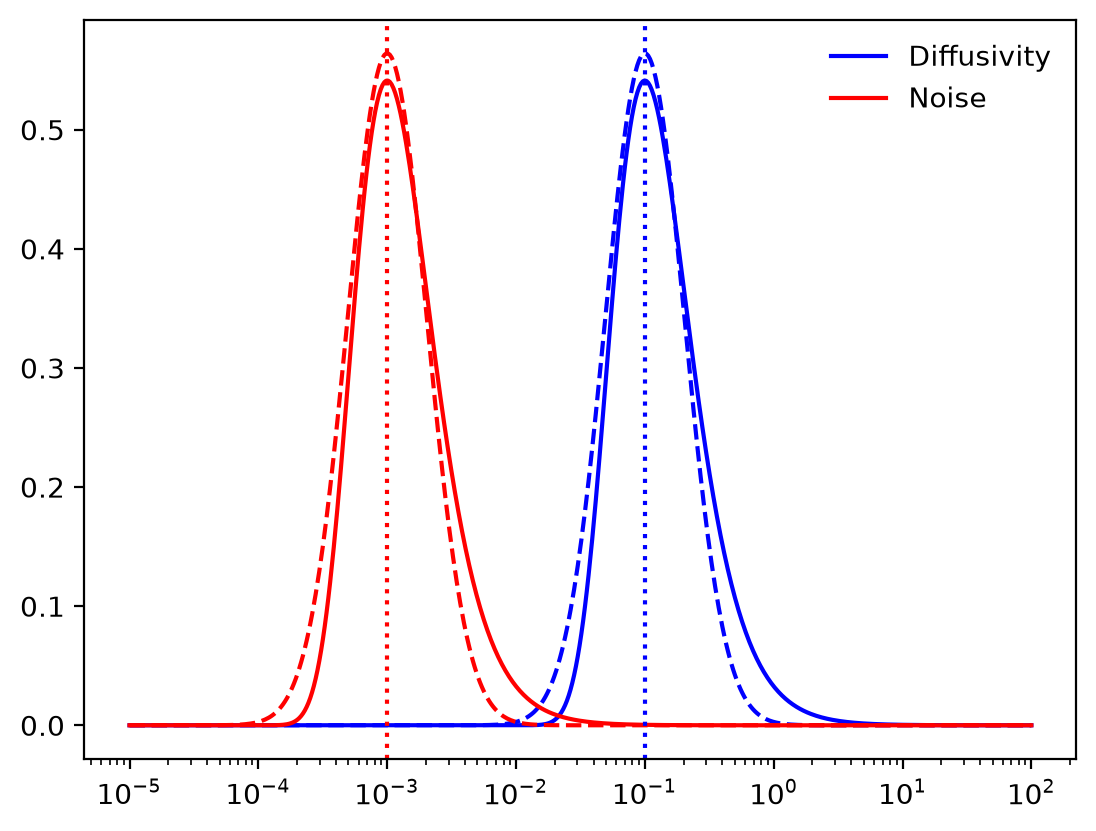

In [47]:
Ds = np.logspace(-5,2,500)
pdflnD = Ds * stats.invgamma.pdf(Ds, alpha_D, scale=beta_D)
pdflnD2 = Ds * stats.lognorm.pdf(Ds, np.sqrt(1/alpha_D), scale=Dtheta)

Rs = np.logspace(-5,2,500)
pdflnR = Rs * stats.invgamma.pdf(Rs, alpha_R, scale=beta_R)
pdflnR2 = Rs * stats.lognorm.pdf(Rs, np.sqrt(1/alpha_R), scale=R)

plt.semilogx(Ds, pdflnD, 'b-', label='Diffusivity')
plt.semilogx(Ds, pdflnD2, 'b--')
plt.semilogx(Rs, pdflnR, 'r-', label='Noise')
plt.semilogx(Rs, pdflnR2, 'r--')
plt.axvline(x=Dtheta, color='b', ls=':')
plt.axvline(x=R, color='r', ls=':')
plt.legend(frameon=False);

### Visualize Posteriors

phase velocity = 1.02654 +/- 0.06372
diffusivity = 0.10255 exp(+/- 0.05313)
noise var = 0.00108 exp(+/- 0.04411)
CPU times: user 957 ms, sys: 9.99 ms, total: 967 ms
Wall time: 980 ms


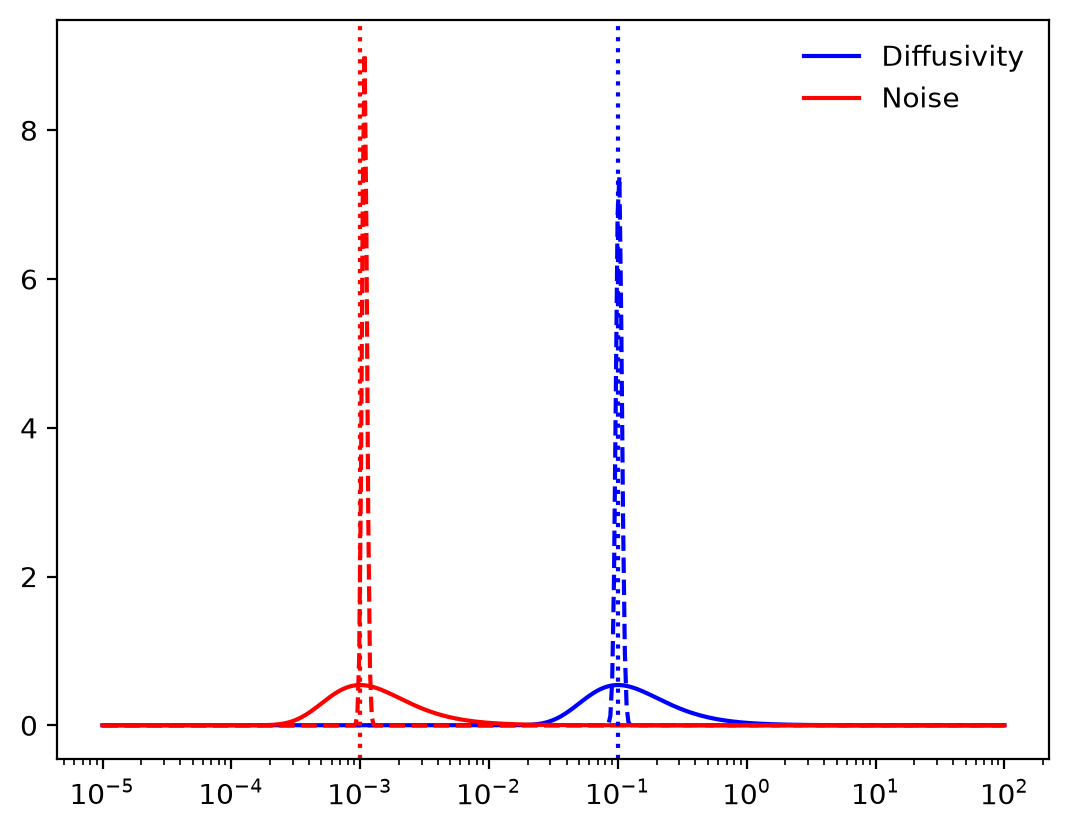

In [48]:
%%time
out = SPNM.simulate_and_infer(param, N, dt, rng, priors, max_iter=max_iter, tol=tol)

print(f"phase velocity = {out['lambda_map_nonlinear'][0]:.5f} +/- {out['stderr'][0]:.5f}")
print(f"diffusivity = {out['lambda_map_nonlinear_natural'][1]:.5f} exp(+/- {out['stderr'][1]:.5f})")
print(f"noise var = {out['lambda_map_nonlinear_natural'][2]:.5f} exp(+/- {out['stderr'][2]:.5f})")

pdflnD2 = Ds * stats.lognorm.pdf(Ds, out['stderr'][1], scale=out['lambda_map_frozen_natural'][1])
pdflnR2 = Rs * stats.lognorm.pdf(Rs, out['stderr'][2], scale=out['lambda_map_frozen_natural'][2])

plt.semilogx(Ds, pdflnD, 'b-', label='Diffusivity')
plt.semilogx(Ds, pdflnD2, 'b--')
plt.semilogx(Rs, pdflnR, 'r-', label='Noise')
plt.semilogx(Rs, pdflnR2, 'r--')
plt.axvline(x=Dtheta, color='b', ls=':')
plt.axvline(x=R, color='r', ls=':')
plt.legend(frameon=False);

phase velocity = 1.06517 +/- 0.06371
diffusivity = 0.10178 exp(+/- 0.05333)
noise var = 0.00111 exp(+/- 0.04410)
CPU times: user 273 ms, sys: 16.7 ms, total: 290 ms
Wall time: 293 ms


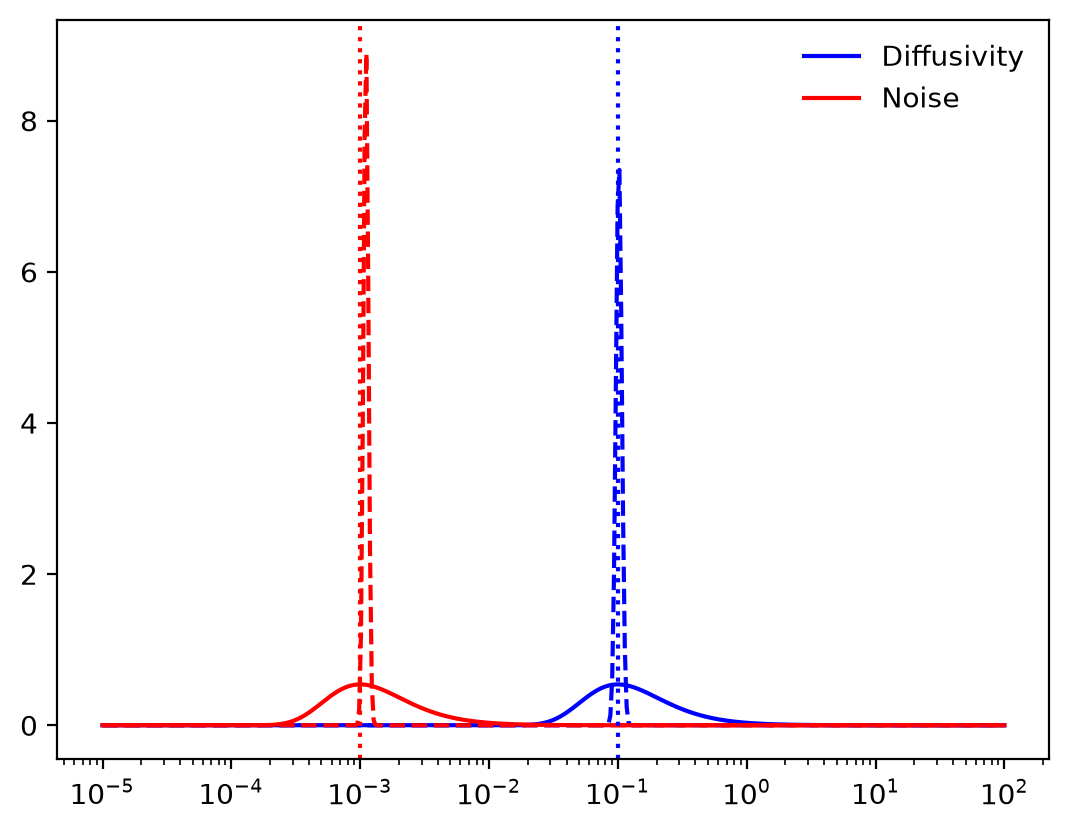

In [9]:
%%time
out = SPNM.simulate_and_infer(param, N, dt, rng, priors, max_iter=max_iter, tol=tol, nonlinear_inference="em")

print(f"phase velocity = {out['lambda_map_nonlinear'][0]:.5f} +/- {out['stderr'][0]:.5f}")
print(f"diffusivity = {out['lambda_map_nonlinear_natural'][1]:.5f} exp(+/- {out['stderr'][1]:.5f})")
print(f"noise var = {out['lambda_map_nonlinear_natural'][2]:.5f} exp(+/- {out['stderr'][2]:.5f})")

pdflnD2 = Ds * stats.lognorm.pdf(Ds, out['stderr'][1], scale=out['lambda_map_frozen_natural'][1])
pdflnR2 = Rs * stats.lognorm.pdf(Rs, out['stderr'][2], scale=out['lambda_map_frozen_natural'][2])

plt.semilogx(Ds, pdflnD, 'b-', label='Diffusivity')
plt.semilogx(Ds, pdflnD2, 'b--')
plt.semilogx(Rs, pdflnR, 'r-', label='Noise')
plt.semilogx(Rs, pdflnR2, 'r--')
plt.axvline(x=Dtheta, color='b', ls=':')
plt.axvline(x=R, color='r', ls=':')
plt.legend(frameon=False);

## Effect of $N$

For constant $\Delta t$, $\omega$, $D_\theta$, $R$. Sweep number of data points from $N_{\min}$ to $N_{\max}$.

In [10]:
print(np.sqrt(2*1/(10*1)), np.sqrt(2*1/(1e4*1)))
print(np.sqrt(2*Dtheta/(20*dt)), np.sqrt(2*Dtheta/(2e4*dt)))

0.4472135954999579 0.01414213562373095
0.4472135954999579 0.01414213562373095


In [11]:
rng = np.random.default_rng(seed=326890)   # PCG64 by default

# Model Parameters 
omega = 1.    # drift velocity (scaled to 1)
Dtheta = 0.1  # phase diffusivity 
R = 0.001     # noise variance, radians^2
param = (omega,Dtheta,R)

# Simulation Parameters
dt = 0.05 # time step
max_iter = 2000
tol = 1e-5

N_points = 60
N_min = 20
N_max = 20000
Ns = np.round(np.logspace(np.log10(N_min), np.log10(N_max), N_points)).astype(int)

omegas  = np.zeros((N_points,))
omega_errs  = np.zeros((N_points,))
Dthetas  = np.zeros((N_points,))
lnDtheta_errs  = np.zeros((N_points,))
Rs  = np.zeros((N_points,))
lnR_errs  = np.zeros((N_points,))

for j in range(N_points):
    out = SPNM.simulate_and_infer(param, Ns[j], dt, rng, priors, max_iter=max_iter, tol=tol)
  
    omegas[j] = out['lambda_map_nonlinear_natural'][0]
    omega_errs[j] =out['stderr'][0]

    Dthetas[j] = out['lambda_map_nonlinear_natural'][1]
    lnDtheta_errs[j] = out['stderr'][1]

    Rs[j] = out['lambda_map_nonlinear_natural'][2]
    lnR_errs[j] = out['stderr'][2]

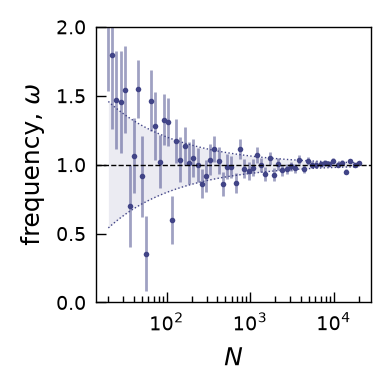

In [12]:
# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.fill_between(Ns, omega + np.sqrt(2*Dtheta/((Ns-1)*dt)), 
                 omega - np.sqrt(2*Dtheta/((Ns-1)*dt)), 
                 color=cmap(0.2), alpha=0.1, lw=0)
plt.plot(Ns, omega + np.sqrt(2*Dtheta/((Ns-1)*dt)), ':', c=cmap(0.2), lw=0.5)
plt.plot(Ns, omega - np.sqrt(2*Dtheta/((Ns-1)*dt)), ':', c=cmap(0.2), lw=0.5)

plt.plot(Ns, omegas, 'o', mew=0, ms=2, color=cmap(0.2))
plt.errorbar(Ns, omegas, omega_errs, fmt='None', color=cmap(0.2), lw=1, alpha=0.5)

# prior
# plt.axhline(y=mu_omega - sigma_omega, color='k', lw=0.5, ls='--')
# plt.axhline(y=mu_omega + sigma_omega, color='k', lw=0.5, ls='--')

# true mean
plt.axhline(y=omega, color='k', lw=0.5, ls='--')

# Set axis labels with font size 9 pt
ax.set_ylabel(r'frequency, $\omega$', fontsize=9)
ax.set_xlabel(r'$N$', fontsize=9)
ax.set_xscale('log')
ax.set_ylim(0,2)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)


plt.savefig('plots/frequency_vs_N.pdf')

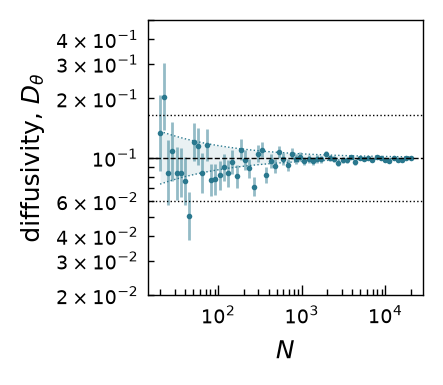

In [13]:
Dtheta_errs = np.vstack((Dthetas - np.exp(np.log(Dthetas) - lnDtheta_errs),
                         np.exp(np.log(Dthetas) + lnDtheta_errs) - Dthetas))


# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])


# Plot the data
plt.plot(Ns, Dthetas, 'o', mew=0, ms=2, color=cmap(0.4))
plt.errorbar(Ns, Dthetas, Dtheta_errs, fmt='None', lw=1, alpha=0.5, color=cmap(0.4))

plt.fill_between(Ns,  np.exp(np.log(Dtheta) - np.sqrt(2/(Ns+3))), 
                 np.exp(np.log(Dtheta) + np.sqrt(2/(Ns+1))), 
                 color=cmap(0.4), alpha=0.1, lw=0)
plt.plot(Ns, np.exp(np.log(Dtheta) - np.sqrt(2/(Ns+1))), ':', c=cmap(0.4), lw=0.5)
plt.plot(Ns, np.exp(np.log(Dtheta) + np.sqrt(2/(Ns+1))), ':', c=cmap(0.4), lw=0.5)

# prior
plt.axhline(y=np.exp(np.log(beta_D/alpha_D) + 1/alpha_D), color='k', lw=0.5, ls=':')
plt.axhline(y=np.exp(np.log(beta_D/alpha_D) - 1/alpha_D), color='k', lw=0.5, ls=':')

# true mean
plt.axhline(y=Dtheta, color='k', lw=0.5, ls='--')

# Set axis labels with font size 9 pt
ax.set_ylabel(r'diffusivity, $D_\theta$', fontsize=9)
ax.set_xlabel(r'$N$', fontsize=9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(Dtheta/5,Dtheta*5)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/diffusivity_vs_N.pdf')

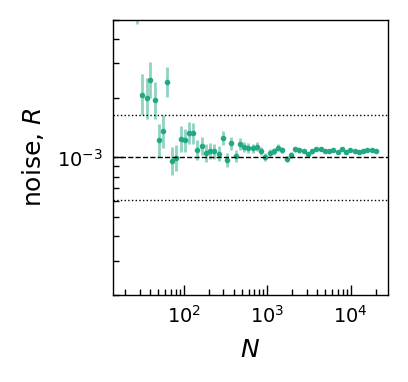

In [ ]:
R_errs = np.vstack((Rs - np.exp(np.log(Rs) - lnR_errs),
                    np.exp(np.log(Rs) + lnR_errs) - Rs))


# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(Ns, Rs, 'o', mew=0, ms=2, color=cmap(0.6))
plt.errorbar(Ns, Rs, R_errs, fmt='None', lw=1, alpha=0.5, color=cmap(0.6))

# plt.fill_between(Ns,  np.exp(np.log(R) - np.sqrt(2/(Ns+3))), 
#                  np.exp(np.log(R) + np.sqrt(2/(Ns+1))), 
#                  color=cmap(0.4), alpha=0.1, lw=0)
# plt.plot(Ns, np.exp(np.log(Dtheta) - np.sqrt(2/(Ns+1))), 'k:', lw=0.5)
# plt.plot(Ns, np.exp(np.log(Dtheta) + np.sqrt(2/(Ns+1))), 'k:', lw=0.5)

# prior
plt.axhline(y=np.exp(np.log(beta_R/alpha_R) + 1/alpha_R), color='k', lw=0.5, ls=':')
plt.axhline(y=np.exp(np.log(beta_R/alpha_R) - 1/alpha_R), color='k', lw=0.5, ls=':')

# true mean
plt.axhline(y=R, color='k', lw=0.5, ls='--')

# Set axis labels with font size 9 pt
ax.set_ylabel(r'noise, $R$', fontsize=9)
ax.set_xlabel(r'$N$', fontsize=9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(R/5,R*5)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/noise_vs_N.pdf')

## Effect of time step $\Delta t$

For constant $N$, $\omega$, $D_\theta$, $R$

In [49]:
rng = np.random.default_rng(seed=326890)   # PCG64 by default

# Model Parameters 
omega = 1.    # drift velocity
Dtheta = 0.1  # phase diffusivity 
R = 0.001     # noise variance, radians^2
param = (omega,Dtheta,R)

# Simulation Parameters
N = 1000 # number of data points

beta_D = alpha_D*Dtheta  # mode = alpha/beta for log parameterization
beta_R = alpha_R*R       # mode = alpha/beta for log parameterization
param_priors= (mu_omega, sigma_omega, alpha_D, beta_D, alpha_R, beta_R)
priors = state_priors + param_priors
    
dt_points = 60
dt_min = 0.05/100
dt_max = 0.05*10
dts = np.logspace(np.log10(dt_min), np.log10(dt_max), dt_points)
omegas = np.zeros((dt_points,))
omega_errs = np.zeros((dt_points,))
Dthetas = np.zeros((dt_points,))
lnDtheta_errs = np.zeros((dt_points,))
Rs = np.zeros((dt_points,))
lnR_errs = np.zeros((dt_points,))

for j in range(dt_points):
    out = SPNM.simulate_and_infer(param, N, dts[j], rng, priors, 
                                  max_iter=max_iter, tol=tol, nonlinear_inference="em")
  
    omegas[j] = out['lambda_map_nonlinear_natural'][0]
    omega_errs[j] =out['stderr'][0]

    Dthetas[j] = out['lambda_map_nonlinear_natural'][1]
    lnDtheta_errs[j] = out['stderr'][1]

    Rs[j] = out['lambda_map_nonlinear_natural'][2]
    lnR_errs[j] = out['stderr'][2]

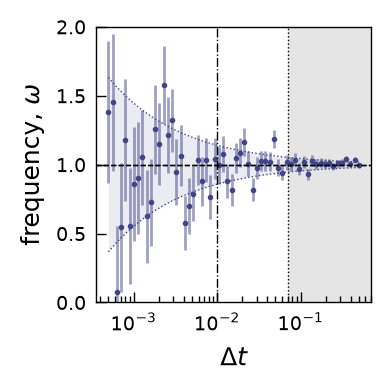

In [59]:
# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.fill_between(dts, omega + np.sqrt(2*Dtheta/((N-1)*dts)), 
                 omega - np.sqrt(2*Dtheta/((N-1)*dts)), 
                 color=cmap(0.2), alpha=0.1, lw=0)
plt.plot(dts, omega + np.sqrt(2*Dtheta/((N-1)*dts)), ':', lw=0.5, c=cmap(0.2))
plt.plot(dts, omega - np.sqrt(2*Dtheta/((N-1)*dts)), ':', lw=0.5, c=cmap(0.2))

plt.plot(dts, omegas, 'o', mew=0, ms=2, color=cmap(0.2))
plt.errorbar(dts, omegas, omega_errs,  fmt='None', color=cmap(0.2), lw=1, alpha=0.5)
plt.axhline(y=omega, color='k', lw=0.5, ls='--')

# prior
# plt.axhline(y=mu_omega - sigma_omega, color='k', lw=0.5, ls='--')
# plt.axhline(y=mu_omega + sigma_omega, color='k', lw=0.5, ls='--')

# true mean
plt.axhline(y=omega, color='k', lw=0.5, ls='--')

# cross-over
gamma = 0.2 
# print(gamma**0.5 * R**0.25 / omega, gamma**2/(2*Dtheta), gamma**4/(2*Dtheta*R))
# plt.axvline(x=gamma**0.5 * R**0.25 / omega, color='k', lw=0.5, ls=':', zorder=-10)
# plt.axvspan(gamma**0.5 * R**0.25 / omega, dts[-1]*np.sqrt(2), color='k', alpha=0.1, lw=0, zorder=-10)
# plt.text(gamma**0.5 * R**0.25 / omega, 0.4*Dtheta, r'$\frac{\varepsilon^{1/2} R^{1/4}}{\omega}$', 
#          horizontalalignment='center', verticalalignment='center',fontsize=10)

plt.axvline(x=gamma**0.5 * R**0.5 / (2*Dtheta), color='k', lw=0.5, ls=':', zorder=-10)
plt.axvspan(gamma**0.5 * R**0.5 / (2*Dtheta), dts[-1]*np.sqrt(2), color='k', alpha=0.1, lw=0, zorder=-10)

plt.axvline(x=R/Dtheta, color='k', lw=0.5, ls='-.')
# plt.text(R/Dtheta, Dtheta/0.4, r'$\frac{R}{D_\theta}$', horizontalalignment='center', 
#          verticalalignment='center',fontsize=10, bbox=dict(facecolor='white', linewidth=0, alpha=1.0))

# Set axis labels with font size 9 pt
ax.set_ylabel(r'frequency, $\omega$', fontsize=9)
ax.set_xlabel(r'$\Delta t$', fontsize=9)
ax.set_xscale('log')
ax.set_ylim(0,2)
ax.set_xlim(dts[0]/np.sqrt(2),dts[-1]*np.sqrt(2))

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/frequency_vs_dt.pdf')

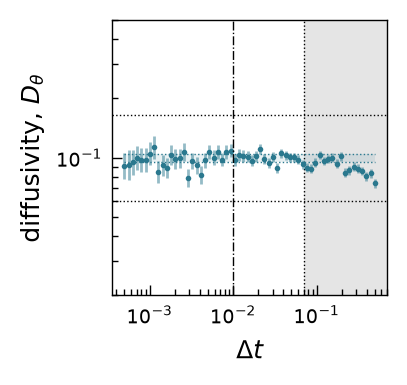

In [60]:
Dtheta_errs = np.vstack((Dthetas - np.exp(np.log(Dthetas) - lnDtheta_errs),
                         np.exp(np.log(Dthetas) + lnDtheta_errs) - Dthetas))


# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])


# Plot the data
plt.plot(dts, Dthetas, 'o', mew=0, ms=2, color=cmap(0.4))
plt.errorbar(dts, Dthetas, Dtheta_errs, fmt='None', lw=1, alpha=0.5, color=cmap(0.4))

plt.fill_between(dts,  np.exp(np.log(Dtheta) - np.sqrt(2/(N+3))), 
                 np.exp(np.log(Dtheta) + np.sqrt(2/(N+1))), 
                 color=cmap(0.4), alpha=0.1, lw=0)
plt.plot(dts, np.exp(np.log(Dtheta) - np.sqrt(2/(N+1))) * np.ones_like(dts), ':', lw=0.5, c=cmap(0.4))
plt.plot(dts, np.exp(np.log(Dtheta) + np.sqrt(2/(N+1))) * np.ones_like(dts), ':', lw=0.5, c=cmap(0.4))

# prior
plt.axhline(y=np.exp(np.log(beta_D/alpha_D) + 1/alpha_D), color='k', lw=0.5, ls=':')
plt.axhline(y=np.exp(np.log(beta_D/alpha_D) - 1/alpha_D), color='k', lw=0.5, ls=':')

# true mean
plt.axhline(y=1, color='k', lw=0.5, ls='--')

# cross-over
gamma = 0.2 
# print(gamma**0.5 * R**0.25 / omega, gamma**2/(2*Dtheta), gamma**4/(2*Dtheta*R))
# plt.axvline(x=gamma**0.5 * R**0.25 / omega, color='k', lw=0.5, ls=':', zorder=-10)
# plt.axvspan(gamma**0.5 * R**0.25 / omega, dts[-1]*np.sqrt(2), color='k', alpha=0.1, lw=0, zorder=-10)
# plt.text(gamma**0.5 * R**0.25 / omega, 0.4*Dtheta, r'$\frac{\varepsilon^{1/2} R^{1/4}}{\omega}$', 
#          horizontalalignment='center', verticalalignment='center',fontsize=10)

plt.axvline(x=gamma**0.5 * R**0.5 / (2*Dtheta), color='k', lw=0.5, ls=':', zorder=-10)
plt.axvspan(gamma**0.5 * R**0.5 / (2*Dtheta), dts[-1]*np.sqrt(2), color='k', alpha=0.1, lw=0, zorder=-10)

plt.axvline(x=R/Dtheta, color='k', lw=0.5, ls='-.')
# plt.text(R/Dtheta, Dtheta/0.4, r'$\frac{R}{D_\theta}$', horizontalalignment='center', 
#          verticalalignment='center',fontsize=10, bbox=dict(facecolor='white', linewidth=0, alpha=1.0))

# Set axis labels with font size 9 pt
ax.set_ylabel(r'diffusivity, $D_\theta$', fontsize=9)
ax.set_xlabel(r'$\Delta t$', fontsize=9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(Dtheta/5,Dtheta*5)
ax.set_xlim(dts[0]/np.sqrt(2),dts[-1]*np.sqrt(2))

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in', labelleft=False)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/diffusivity_vs_dt.pdf')

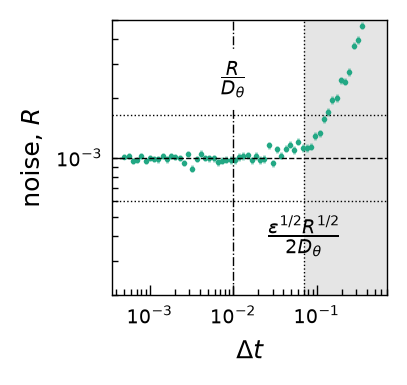

In [61]:
R_errs = np.vstack((Rs - np.exp(np.log(Rs) - lnR_errs),
                    np.exp(np.log(Rs) + lnR_errs) - Rs))


# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(dts, Rs, 'o', mew=0, ms=2, color=cmap(0.6))
plt.errorbar(dts, Rs, R_errs, fmt='None', lw=1, alpha=0.5, color=cmap(0.6))

# prior
plt.axhline(y=np.exp(np.log(beta_R/alpha_R) + 1/alpha_R), color='k', lw=0.5, ls=':')
plt.axhline(y=np.exp(np.log(beta_R/alpha_R) - 1/alpha_R), color='k', lw=0.5, ls=':')

# true mean
plt.axhline(y=R, color='k', lw=0.5, ls='--')

# cross-over
gamma = 0.2 
# plt.axvline(x=gamma**0.5 * R**0.25 / omega, color='k', lw=0.5, ls=':', zorder=-10)
# plt.axvspan(gamma**0.5 * R**0.25 / omega, dts[-1]*np.sqrt(2), color='k', alpha=0.1, lw=0, zorder=-10)
# plt.text(gamma**0.5 * R**0.25 / omega, 0.4*R, r'$\frac{\varepsilon^{1/2} R^{1/4}}{\omega}$', 
#          horizontalalignment='center', verticalalignment='center',fontsize=10)
    
plt.axvline(x=gamma**0.5 * R**0.5 / (2*Dtheta), color='k', lw=0.5, ls=':', zorder=-10)
plt.axvspan(gamma**0.5 * R**0.5 / (2*Dtheta), dts[-1]*np.sqrt(2), color='k', alpha=0.1, lw=0, zorder=-10)
plt.text(gamma**0.5 * R**0.5 / (2*Dtheta), 0.4*R, r'$\frac{\varepsilon^{1/2} R^{1/2}}{2D_\theta}$', 
         horizontalalignment='center', verticalalignment='center',fontsize=10)

plt.axvline(x=R/Dtheta, color='k', lw=0.5, ls='-.')
plt.text(R/Dtheta, R/0.4, r'$\frac{R}{D_\theta}$', horizontalalignment='center', 
         verticalalignment='center',fontsize=10, bbox=dict(facecolor='white', linewidth=0, alpha=1.0))

# Set axis labels with font size 9 pt
ax.set_ylabel(r'noise, $R$', fontsize=9)
ax.set_xlabel(r'$\Delta t$', fontsize=9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(R/5,R*5)
ax.set_xlim(dts[0]/np.sqrt(2),dts[-1]*np.sqrt(2))

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in', labelleft=False)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/noise_vs_dt.pdf')

## Effect of noise $R$

For constant $N$, $\Delta t$, $\omega$, $D_\theta$

In [72]:
rng = np.random.default_rng(seed=326890)   # PCG64 by default

# Model Parameters 
omega = 1.    # drift velocity
Dtheta = 0.1  # phase diffusivity 
R = 0.001      # noise variance
param = (omega,Dtheta,R)

# Simulation Parameters
N = 1000 # number of data points
dt = 0.05 # time step, seconds
max_iter = 1000
    
R_points = 60
R_min = R / 10**2
R_max = R * 100**2
R_trues = np.logspace(np.log10(R_min), np.log10(R_max), R_points)

omegas  = np.zeros((R_points,))
omega_errs  = np.zeros((R_points,))
Dthetas  = np.zeros((R_points,))
lnDtheta_errs  = np.zeros((R_points,))
Rs  = np.zeros((R_points,))
lnR_errs  = np.zeros((R_points,))

beta_D = alpha_D*Dtheta  # mode = alpha/beta for log parameterization
beta_R = alpha_R*R       # mode = alpha/beta for log parameterization

for j in range(R_points):
    beta_R = alpha_R*R_trues[j]  # mode = alpha/beta for log parameterization   
    param_priors= (mu_omega, sigma_omega, alpha_D, beta_D, alpha_R, beta_R)
    priors = state_priors + param_priors

    param = (omega, Dtheta, R_trues[j])
    out = SPNM.simulate_and_infer(param, N, dt, rng, priors, max_iter=max_iter, tol=tol, nonlinear_inference="em")
  
    omegas[j] = out['lambda_map_nonlinear_natural'][0]
    omega_errs[j] = out['stderr'][0]

    Dthetas[j] = out['lambda_map_nonlinear_natural'][1]
    lnDtheta_errs[j] = out['stderr'][1]

    Rs[j] = out['lambda_map_nonlinear_natural'][2]
    lnR_errs[j] = out['stderr'][2]

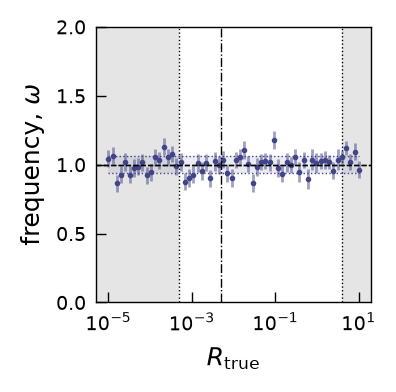

In [83]:
# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.fill_between(R_trues, omega + np.sqrt(2*Dtheta/((N-1)*dt)), 
                 omega - np.sqrt(2*Dtheta/((N-1)*dt)), 
                 color=cmap(0.2), alpha=0.1, lw=0)
plt.plot(R_trues, omega + np.sqrt(2*Dtheta/((N-1)*dt)) * np.ones_like(R_trues), ':', lw=0.5, c=cmap(0.2))
plt.plot(R_trues, omega - np.sqrt(2*Dtheta/((N-1)*dt)) * np.ones_like(R_trues), ':', lw=0.5, c=cmap(0.2))

plt.plot(R_trues, omegas, 'o', mew=0, ms=2, color=cmap(0.2))
plt.errorbar(R_trues, omegas, omega_errs,  fmt='None', color=cmap(0.2), lw=1, alpha=0.5)
plt.axhline(y=omega, color='k', lw=0.5, ls='--')

# true mean
plt.axhline(y=omega, color='k', lw=0.5, ls='--')

# cross-over
gamma = 0.2
plt.axvline(x=gamma**2 / (2*Dtheta*dt), color='k', lw=0.5, ls=':', zorder=-10)
plt.axvspan(gamma**2 / (2*Dtheta*dt), R_trues[-1]*2, color='k', alpha=0.1, lw=0, zorder=-10)

# plt.axvline(x=(omega*dt)**4/gamma**2, color='k', lw=0.5, ls=':', zorder=-10)
# plt.axvspan(R_trues[0]/2, (omega*dt)**4/gamma**2, color='k', alpha=0.1, lw=0, zorder=-10)

plt.axvline(x=(2*Dtheta*dt)**2/gamma, color='k', lw=0.5, ls=':', zorder=-10)
plt.axvspan(R_trues[0]/2, (2*Dtheta*dt)**2/gamma, color='k', alpha=0.1, lw=0, zorder=-10)

plt.axvline(x=Dtheta*dt, color='k', lw=0.5, ls='-.')

# Set axis labels with font size 9 pt
ax.set_ylabel(r'frequency, $\omega$', fontsize=9)
ax.set_xlabel(r'$R_\mathrm{true}$', fontsize=9)
ax.set_xscale('log')
ax.set_ylim(0,2)
ax.set_xlim(R_trues[0]/2, R_trues[-1]*2)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')
ax.set_xticks([0.00001, 0.001, 0.1, 10])

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/frequency_vs_R.pdf')

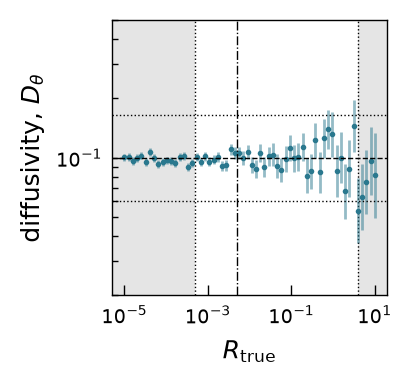

In [82]:
Dtheta_errs = np.vstack((Dthetas - np.exp(np.log(Dthetas) - lnDtheta_errs),
                         np.exp(np.log(Dthetas) + lnDtheta_errs) - Dthetas))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(R_trues, Dthetas, 'o', mew=0, ms=2, color=cmap(0.4))
plt.errorbar(R_trues, Dthetas, Dtheta_errs, fmt='None', lw=1, alpha=0.5, color=cmap(0.4))

# prior
plt.axhline(y=np.exp(np.log(beta_D/alpha_D) + 1/alpha_D), color='k', lw=0.5, ls=':')
plt.axhline(y=np.exp(np.log(beta_D/alpha_D) - 1/alpha_D), color='k', lw=0.5, ls=':')

# true mean
plt.axhline(y=Dtheta, color='k', lw=0.5, ls='--')

# cross-over
gamma = 0.2
plt.axvline(x=gamma**2 / (2*Dtheta*dt), color='k', lw=0.5, ls=':', zorder=-10)
plt.axvspan(gamma**2 / (2*Dtheta*dt), R_trues[-1]*2, color='k', alpha=0.1, lw=0, zorder=-10)
# plt.text(gamma**4 / (2*Dtheta*dt), 0.4*Dtheta, r'$\frac{\varepsilon^4}{2 D_\theta \Delta t}$', horizontalalignment='center', verticalalignment='center',fontsize=10)

# plt.axvline(x=(omega*dt)**4/gamma**2, color='k', lw=0.5, ls=':', zorder=-10)
# plt.axvspan(R_trues[0]/2, (omega*dt)**4/gamma**2, color='k', alpha=0.1, lw=0, zorder=-10)
# plt.text((omega*dt)**4/gamma**2, 0.4*Dtheta, r'$\frac{(\omega \Delta t)^4}{\varepsilon^2}$', horizontalalignment='center', verticalalignment='center', fontsize=10)

plt.axvline(x=(2*Dtheta*dt)**2/gamma, color='k', lw=0.5, ls=':', zorder=-10)
plt.axvspan(R_trues[0]/2, (2*Dtheta*dt)**2/gamma, color='k', alpha=0.1, lw=0, zorder=-10)

plt.axvline(x=Dtheta*dt, color='k', lw=0.5, ls='-.')
# plt.text(Dtheta*dt, Dtheta/0.4, r'$D_\theta \Delta t$', horizontalalignment='center', verticalalignment='center', fontsize=8, 
#          bbox=dict(facecolor='white', linewidth=0, alpha=1.0))

# Set axis labels with font size 9 pt
ax.set_ylabel(r'diffusivity, $D_\theta$', fontsize=9)
ax.set_xlabel(r'$R_\text{true}$', fontsize=9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(Dtheta/5,Dtheta*5)
ax.set_xlim(R_trues[0]/2, R_trues[-1]*2)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in', labelleft=False)
ax.set_xticks([0.00001, 0.001, 0.1, 10])

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/diffusivity_vs_R.pdf')

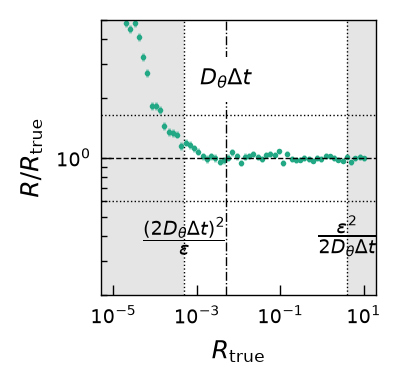

In [81]:
R_errs = np.vstack((Rs - np.exp(np.log(Rs) - lnR_errs),
                    np.exp(np.log(Rs) + lnR_errs) - Rs))


# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(R_trues, Rs/R_trues, 'o', mew=0, ms=2, color=cmap(0.6))
plt.errorbar(R_trues, Rs/R_trues, R_errs/R_trues, fmt='None', lw=1, alpha=0.5, color=cmap(0.6))

# prior
plt.axhline(y=np.exp( 1/alpha_R), color='k', lw=0.5, ls=':')
plt.axhline(y=np.exp(- 1/alpha_R), color='k', lw=0.5, ls=':')

# true mean
plt.axhline(y=1, color='k', lw=0.5, ls='--')

# cross-over
gamma = 0.2

plt.axvline(x=gamma**2 / (2*Dtheta*dt), color='k', lw=0.5, ls=':', zorder=-10)
plt.axvspan(gamma**2 / (2*Dtheta*dt), R_trues[-1]*2, color='k', alpha=0.1, lw=0, zorder=-10)
plt.text(gamma**2 / (2*Dtheta*dt), 0.4, r'$\frac{\varepsilon^2}{2 D_\theta \Delta t}$', horizontalalignment='center', verticalalignment='center',fontsize=10)

# plt.axvline(x=(omega*dt)**4/gamma**2, color='k', lw=0.5, ls=':', zorder=-10)
# plt.axvspan(R_trues[0]/2, (omega*dt)**4/gamma**2, color='k', alpha=0.1, lw=0, zorder=-10)
# plt.text((omega*dt)**4/gamma**2, 0.4, r'$\frac{(\omega \Delta t)^4}{\varepsilon^2}$', horizontalalignment='center', verticalalignment='center', fontsize=10)

plt.axvline(x=(2*Dtheta*dt)**2/gamma, color='k', lw=0.5, ls=':', zorder=-10)
plt.axvspan(R_trues[0]/2, (2*Dtheta*dt)**2/gamma, color='k', alpha=0.1, lw=0, zorder=-10)
plt.text((2*Dtheta*dt)**2/gamma, 0.4, r'$\frac{(2 D_\theta \Delta t)^2}{\varepsilon}$', horizontalalignment='center', verticalalignment='center', fontsize=10)

plt.axvline(x=Dtheta*dt, color='k', lw=0.5, ls='-.')
plt.text(Dtheta*dt, 1/0.4, r'$D_\theta \Delta t$', horizontalalignment='center', verticalalignment='center', fontsize=8, 
         bbox=dict(facecolor='white', linewidth=0, alpha=1.0))

# Set axis labels with font size 9 pt
ax.set_ylabel(r'$R / R_{\text{true}}$', fontsize=9)
ax.set_xlabel(r'$R_{\mathrm{true}}$', fontsize=9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1/5,1*5)
ax.set_xlim(R_trues[0]/2, R_trues[-1]*2)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in', labelleft=False)
ax.set_xticks([0.00001, 0.001, 0.1, 10])

# ax.set_xticks([0.1, 10,  1e3, 1e5])
# ax.set_yticks([1])
# ax.yaxis.set_minor_locator(mticker.NullLocator())

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/noise_vs_R.pdf')

## Effect of diffusivity $D_\theta$

For constant $N$, $\Delta t$, $\omega$, $R$

In [63]:
rng = np.random.default_rng(seed=326890)   # PCG64 by default

# Model Parameters 
omega = 1.    # drift velocity
Dtheta = 0.1  # phase diffusivity 
R = 0.001     # noise variance

# prior hyperparameters
beta_D = alpha_D*Dtheta  # mode = alpha/beta for log parameterization
beta_R = alpha_R*R       # mode = alpha/beta for log parameterization

# Simulation Parameters
N = 1000 # number of data points
dt = 0.05 # time step, seconds
max_iter = 1000

# Diffusivity Sweep
Dtheta_points = 60
Dtheta_min = Dtheta / np.sqrt(1000)
Dtheta_max = Dtheta * np.sqrt(1000)
Dtheta_trues = np.logspace(np.log10(Dtheta_min), np.log10(Dtheta_max), Dtheta_points)

omegas  = np.zeros((Dtheta_points,))
omega_errs  = np.zeros((Dtheta_points,))
Dthetas  = np.zeros((Dtheta_points,))
lnDtheta_errs  = np.zeros((Dtheta_points,))
Rs  = np.zeros((Dtheta_points,))
lnR_errs  = np.zeros((Dtheta_points,))

for j in range(Dtheta_points):
    beta_D = alpha_D*Dtheta_trues[j]  # mode = alpha/beta for log parameterization   
    param_priors= (mu_omega, sigma_omega, alpha_D, beta_D, alpha_R, beta_R)
    priors = state_priors + param_priors

    param = (omega, Dtheta_trues[j], R)
    out = SPNM.simulate_and_infer(param, N, dt, rng, priors, max_iter=max_iter, tol=tol, nonlinear_inference="em")
  
    omegas[j] = out['lambda_map_nonlinear_natural'][0]
    omega_errs[j] = out['stderr'][0]

    Dthetas[j] = out['lambda_map_nonlinear_natural'][1]
    lnDtheta_errs[j] = out['stderr'][1]

    Rs[j] = out['lambda_map_nonlinear_natural'][2]
    lnR_errs[j] = out['stderr'][2]

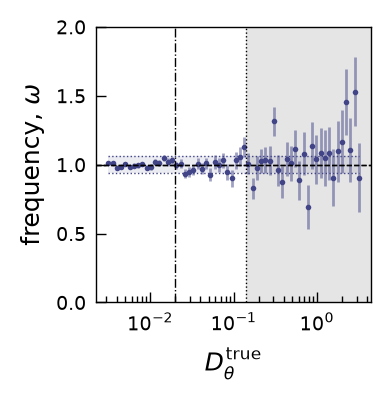

In [71]:
# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.fill_between(Dtheta_trues, omega + np.sqrt(2*Dtheta/((N-1)*dt)), 
                 omega - np.sqrt(2*Dtheta/((N-1)*dt)), 
                 color=cmap(0.2), alpha=0.1, lw=0)
plt.plot(Dtheta_trues, omega + np.sqrt(2*Dtheta/((N-1)*dt)) * np.ones_like(Dtheta_trues), ':', lw=0.5, c=cmap(0.2))
plt.plot(Dtheta_trues, omega - np.sqrt(2*Dtheta/((N-1)*dt)) * np.ones_like(Dtheta_trues), ':', lw=0.5, c=cmap(0.2))

plt.plot(Dtheta_trues, omegas, 'o', mew=0, ms=2, color=cmap(0.2))
plt.errorbar(Dtheta_trues, omegas, omega_errs,  fmt='None', color=cmap(0.2), lw=1, alpha=0.5)
plt.axhline(y=omega, color='k', lw=0.5, ls='--')

# prior
# plt.axhline(y=mu_omega - sigma_omega, color='k', lw=0.5, ls='--')
# plt.axhline(y=mu_omega + sigma_omega, color='k', lw=0.5, ls='--')

# true mean
plt.axhline(y=omega, color='k', lw=0.5, ls='--')
plt.axvline(x=1/(2*dt), color='k', lw=0.5, ls='-.')

# cross-over
# gamma = 0.2
# plt.axvline(x=gamma**2 / (2*dt), color='k', lw=0.5, ls=':')
# plt.axvspan(gamma**2 / (2*dt), Dtheta_trues[-1]*2, color='k', alpha=0.1, lw=0, zorder=-10)

plt.axvline(x=np.sqrt(gamma * R) / (2*dt), color='k', lw=0.5, ls=':')
plt.axvspan(np.sqrt(gamma * R) / (2*dt), Dtheta_trues[-1]*2, color='k', alpha=0.1, lw=0, zorder=-10)

plt.axvline(x=R/dt, color='k', lw=0.5, ls='-.')

# Set axis labels with font size 9 pt
ax.set_ylabel(r'frequency, $\omega$', fontsize=9)
ax.set_xlabel(r'$D_\theta^\text{true}$', fontsize=9)
ax.set_xscale('log')
ax.set_ylim(0,2)
ax.set_xlim(Dtheta_trues[0]/np.sqrt(2), Dtheta_trues[-1]*np.sqrt(2))

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/frequency_vs_Dtheta.pdf')

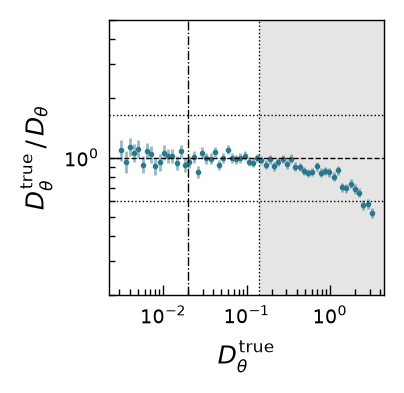

In [70]:
Dtheta_errs = np.vstack((Dthetas - np.exp(np.log(Dthetas) - lnDtheta_errs),
                         np.exp(np.log(Dthetas) + lnDtheta_errs) - Dthetas))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(Dtheta_trues, Dthetas/Dtheta_trues, 'o', mew=0, ms=2, color=cmap(0.4))
plt.errorbar(Dtheta_trues, Dthetas/Dtheta_trues, Dtheta_errs/Dtheta_trues, 
             fmt='None', lw=1, alpha=0.5, color=cmap(0.4))

# plt.fill_between(R_trues,  np.exp(np.log(Dtheta) - np.sqrt(2/(N+3))), 
#                  np.exp(np.log(Dtheta) + np.sqrt(2/(N+1))), 
#                  color=cmap(0.4), alpha=0.1, lw=0)
# plt.plot(R_trues, np.exp(np.log(Dtheta) - np.sqrt(2/(N+1))) * np.ones_like(R_trues), ':', lw=0.5, c=cmap(0.4))
# plt.plot(R_trues, np.exp(np.log(Dtheta) + np.sqrt(2/(N+1))) * np.ones_like(R_trues), ':', lw=0.5, c=cmap(0.4))

# prior
plt.axhline(y=np.exp(1/alpha_D), color='k', lw=0.5, ls=':')
plt.axhline(y=np.exp(-1/alpha_D), color='k', lw=0.5, ls=':')

# true mean
plt.axhline(y=1, color='k', lw=0.5, ls='--')

# cross-over
gamma = 0.2
# plt.axvline(x=gamma**2 / (2*dt), color='k', lw=0.5, ls=':')
# plt.axvspan(gamma**2 / (2*dt), Dtheta_trues[-1]*2, color='k', alpha=0.1, lw=0, zorder=-10)
# plt.text(gamma**2 / (2*dt), 0.4, r'$\frac{\varepsilon^2}{2 \Delta t}$', horizontalalignment='center', verticalalignment='center',fontsize=10)
# plt.axvline(x=gamma**4 / (2*dt*R), color='k', lw=0.5, ls='-.')

plt.axvline(x=np.sqrt(gamma * R) / (2*dt), color='k', lw=0.5, ls=':')
plt.axvspan(np.sqrt(gamma * R) / (2*dt), Dtheta_trues[-1]*2, color='k', alpha=0.1, lw=0, zorder=-10)

plt.axvline(x=R/dt, color='k', lw=0.5, ls='-.')
# plt.text(R/dt, 1/0.4, r'$\frac{R}{\Delta t}$', horizontalalignment='center', verticalalignment='center', fontsize=10,
#          bbox=dict(facecolor='white', linewidth=0, alpha=1.0))

# Set axis labels with font size 9 pt
ax.set_ylabel(r'$D_\theta^{\mathrm{true}}\, / \, D_\theta$', fontsize=9)
ax.set_xlabel(r'$D_\theta^\text{true}$', fontsize=9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1/5,1*5)
ax.set_xlim(Dtheta_trues[0]/np.sqrt(2), Dtheta_trues[-1]*np.sqrt(2))

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in', labelleft=False)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/diffusivity_vs_Dtheta.pdf')

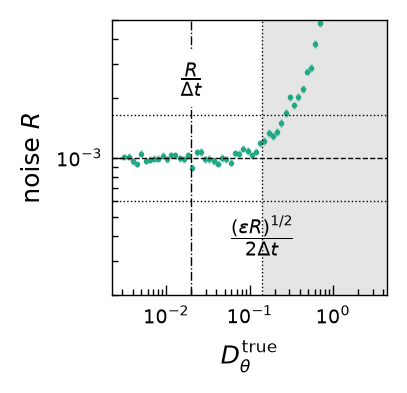

In [68]:
R_errs = np.vstack((Rs - np.exp(np.log(Rs) - lnR_errs),
                    np.exp(np.log(Rs) + lnR_errs) - Rs))


# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(Dtheta_trues, Rs, 'o', mew=0, ms=2, color=cmap(0.6))
plt.errorbar(Dtheta_trues, Rs, R_errs, fmt='None', lw=1, alpha=0.5, color=cmap(0.6))

# prior
plt.axhline(y=np.exp(np.log(beta_R/alpha_R) + 1/alpha_R), color='k', lw=0.5, ls=':')
plt.axhline(y=np.exp(np.log(beta_R/alpha_R) - 1/alpha_R), color='k', lw=0.5, ls=':')

# true mean
plt.axhline(y=R, color='k', lw=0.5, ls='--')

# cross-over
gamma = 0.2
# plt.axvline(x=gamma**2 / (2*dt), color='k', lw=0.5, ls=':')
# plt.axvspan(gamma**2 / (2*dt), Dtheta_trues[-1]*2, color='k', alpha=0.1, lw=0, zorder=-10)
# plt.text(gamma**2 / (2*dt), R*0.4, r'$\frac{\varepsilon^2}{2 \Delta t}$', 
#          horizontalalignment='center', verticalalignment='center',fontsize=10)

plt.axvline(x=np.sqrt(gamma * R) / (2*dt), color='k', lw=0.5, ls=':')
plt.axvspan(np.sqrt(gamma * R) / (2*dt), Dtheta_trues[-1]*2, color='k', alpha=0.1, lw=0, zorder=-10)
plt.text(np.sqrt(gamma * R) / (2*dt), R*0.4, r'$\frac{(\varepsilon R)^{1/2}}{2 \Delta t}$', 
         horizontalalignment='center', verticalalignment='center',fontsize=10)


plt.axvline(x=R/dt, color='k', lw=0.5, ls='-.')
plt.text(R/dt, R/0.4, r'$\frac{R}{\Delta t}$', horizontalalignment='center', verticalalignment='center', fontsize=10,
         bbox=dict(facecolor='white', linewidth=0, alpha=1.0))

# Set axis labels with font size 9 pt
ax.set_ylabel(r'noise $R$', fontsize=9)
ax.set_xlabel(r'$D_{\theta}^\text{true}$', fontsize=9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(R/5,R*5)
ax.set_xlim(Dtheta_trues[0]/np.sqrt(2), Dtheta_trues[-1]*np.sqrt(2))

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in', labelleft=False)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/noise_vs_Dtheta.pdf')